# Chapter 3 · Stationarity and autocorrelation

*Book 21 · Time Series · Shelf V*

**Builds on:** [Chapter 2](02-trend-and-seasonality.ipynb) (trend and season), and correlation
from book 4.
**You will:** compute an autocorrelation by hand, read an ACF plot, make a series stationary by
differencing, and test for it.

Classical models (chapter 4) assume the series is **stationary**: its mean, its variance and its
correlation structure do not depend on *when* you look. Real series rarely are. This chapter is
about measuring how far off they are and how to fix it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf, adfuller, kpss

from ds_toolbox import io, viz

viz.use_style()
rng = np.random.default_rng(21)

## Two reference series

**White noise** is the most stationary thing there is: independent draws. A **random walk** adds
them up, so each value is the last one plus a shock. It has no fixed mean to return to.

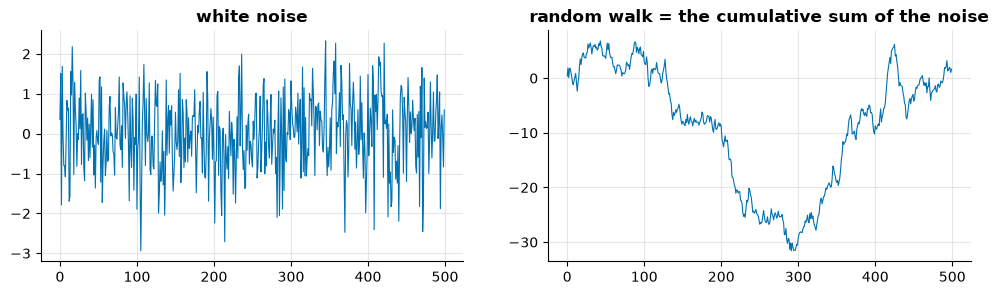

In [2]:
noise = rng.normal(size=500)
walk = noise.cumsum()
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].plot(noise, lw=0.8)
axes[0].set_title("white noise")
axes[1].plot(walk, lw=0.8)
axes[1].set_title("random walk = the cumulative sum of the noise");

## Autocorrelation, by hand

The autocorrelation at lag $k$ is the correlation of the series with itself shifted by $k$:

$$r_k = \frac{\sum_{t=k+1}^{n} (y_t - \bar y)(y_{t-k} - \bar y)}{\sum_{t=1}^{n} (y_t - \bar y)^2}$$

In [3]:
def autocorr(y, k):
    y = np.asarray(y, dtype=float)
    d = y - y.mean()
    return np.sum(d[k:] * d[:-k]) / np.sum(d * d)

for name, y in [("noise", noise), ("walk", walk)]:
    mine = [autocorr(y, k) for k in (1, 2, 10)]
    lib = acf(y, nlags=10)[[1, 2, 10]]
    print(f"{name:5s} by hand {np.round(mine, 3)}  statsmodels {np.round(lib, 3)}")

noise by hand [0.104 0.    0.072]  statsmodels [0.104 0.    0.072]
walk  by hand [0.995 0.989 0.938]  statsmodels [0.995 0.989 0.938]


The two agree. The noise forgets itself at once; the walk remembers almost everything. A slowly
decaying ACF is the classic sign of a non-stationary series.

## The ACF of electricity

On the hourly series, the ACF over two weeks of lags shows the cycles of chapter 2 as peaks:
24 hours, and the largest at 168 hours, one week.

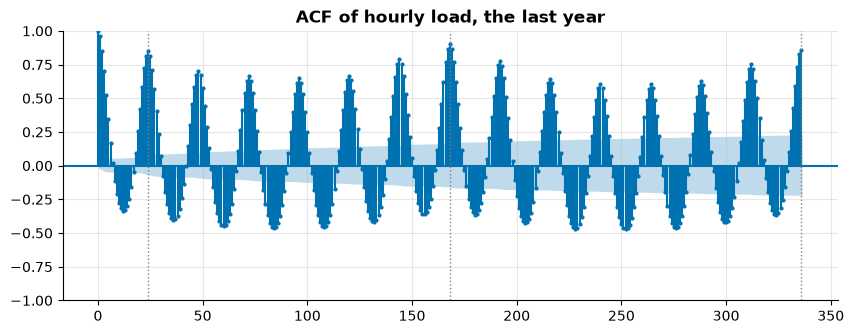

In [4]:
raw = io.load_sample("ewz_zurich_hourly.csv.gz")
hourly = raw.assign(t=pd.to_datetime(raw["hour_utc"], utc=True)).set_index("t")["total_mwh"]
last_year = hourly.iloc[-24 * 365:]
fig, ax = plt.subplots(figsize=(10, 3.5))
plot_acf(last_year, lags=24 * 14, ax=ax, markersize=2, title="ACF of hourly load, the last year")
for k in (24, 168, 336):
    ax.axvline(k, color="0.5", ls=":", lw=1)

## Differencing

Subtracting a lagged copy removes what repeats at that lag. Lag 1 removes the level, lag 24 the
daily cycle, lag 168 the weekly one. Differencing by the season is often all a series needs.

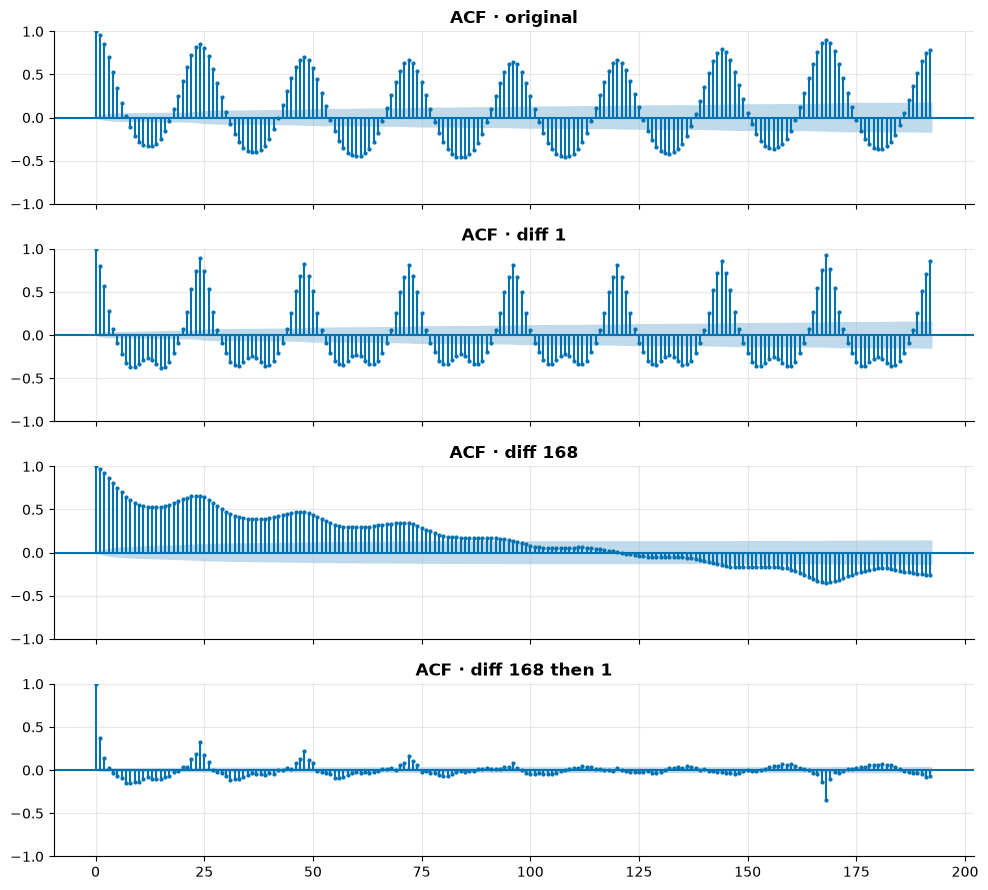

In [5]:
variants = {
    "original": last_year,
    "diff 1": last_year.diff(1),
    "diff 168": last_year.diff(168),
    "diff 168 then 1": last_year.diff(168).diff(1),
}
fig, axes = plt.subplots(len(variants), 1, figsize=(10, 9), sharex=True)
for ax, (name, y) in zip(axes, variants.items(), strict=True):
    plot_acf(y.dropna(), lags=24 * 8, ax=ax, markersize=2, title=f"ACF · {name}")
fig.tight_layout()

## Testing for stationarity

Two tests with opposite null hypotheses, so they are best read together:

- **ADF** (augmented Dickey-Fuller): null = *there is a unit root* (non-stationary). A small
  p-value says stationary.
- **KPSS**: null = *stationary*. A small p-value says non-stationary.

Run on the daily means over ten years:

In [6]:
daily = hourly.tz_convert("Europe/Zurich").resample("D").mean()

def both_tests(y):
    y = y.dropna()
    adf_p = adfuller(y, autolag="AIC", result_object=False)[1]
    with np.errstate(all="ignore"):
        import warnings
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")      # KPSS warns when p is outside its lookup table
            kpss_p = kpss(y, regression="c", nlags="auto")[1]
    return pd.Series({"ADF p": round(adf_p, 3), "KPSS p": round(kpss_p, 3)})

pd.DataFrame({
    "daily": both_tests(daily),
    "daily, diff 7": both_tests(daily.diff(7)),
    "daily, diff 7 then 1": both_tests(daily.diff(7).diff(1)),
}).T

,ADF p,KPSS p
daily,0.0,0.01
"daily, diff 7",0.0,0.10
"daily, diff 7 then 1",0.0,0.10


Read the p-values together. The level series fails KPSS (p at its floor of 0.01) although ADF
rejects a unit root: the weekly season and the yearly cycle move its mean. After the seasonal
difference at lag 7 both tests agree on stationary, and a further first difference adds nothing.
Note that KPSS reports p-values clipped to its table (0.01 to 0.1).

## What to remember

- Stationary = the statistics do not depend on *when*. Trend and season both break it.
- The ACF shows memory; peaks at the season, slow decay for a trend.
- Difference by the season first, and only once more if a test still says so. Test with ADF
  *and* KPSS.

## Exercises

1. Simulate an AR(1) $y_t = 0.9\,y_{t-1} + \varepsilon_t$. What does its ACF look like next to
   the random walk's ($\phi = 1$)?
2. On the hourly series, does `diff(24)` alone make the ACF short-memoried? Why not?
3. Run both tests on the weekly series. How many differences does it need?

**Next:** [Chapter 4 · ARIMA and SARIMA](04-arima-and-sarima.ipynb)